<a href="https://colab.research.google.com/github/Towsif111/An-Architectural-Framework-for-AI-Driven-Security-Operations-Center-/blob/main/Microsoft_GUIDE_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

folder_path = "/content/drive/MyDrive/Microsoft_GUIDE_Dataset"

print(os.listdir(folder_path))

['GUIDE_Train.csv']


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
file_path = "/content/drive/MyDrive/Microsoft_GUIDE_Dataset/GUIDE_Train.csv"

print("Dataset exists:", os.path.exists(file_path))

Dataset exists: True


In [ ]:
df = pd.read_csv(file_path, nrows=1000)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (1000, 45)


In [ ]:
df.head()


,Id,OrgId,IncidentId,AlertId,Timestamp,DetectorId,AlertTitle,Category,MitreTechniques,IncidentGrade,...,ResourceType,Roles,OSFamily,OSVersion,AntispamDirection,SuspicionLevel,LastVerdict,CountryCode,State,City
0,180388628218,0,612,123247,2024-06-04T06:05:15.000Z,7,6,InitialAccess,NaN,TruePositive,...,NaN,NaN,5,66,NaN,NaN,NaN,31,6,3
1,455266534868,88,326,210035,2024-06-14T03:01:25.000Z,58,43,Exfiltration,NaN,FalsePositive,...,NaN,NaN,5,66,NaN,NaN,NaN,242,1445,10630
2,1056561957389,809,58352,712507,2024-06-13T04:52:55.000Z,423,298,InitialAccess,T1189,FalsePositive,...,NaN,NaN,5,66,NaN,Suspicious,Suspicious,242,1445,10630
3,1279900258736,92,32992,774301,2024-06-10T16:39:36.000Z,2,2,CommandAndControl,NaN,BenignPositive,...,NaN,NaN,5,66,NaN,Suspicious,Suspicious,242,1445,10630
4,214748368522,148,4359,188041,2024-06-15T01:08:07.000Z,9,74,Execution,NaN,TruePositive,...,NaN,NaN,5,66,NaN,NaN,NaN,242,1445,10630


In [ ]:
df = pd.read_csv(file_path, nrows=1000)

print("Dataset loaded successfully!")
print("Shape:", df.info)


Dataset loaded successfully!
Shape: <bound method DataFrame.info of                 Id  OrgId  IncidentId  AlertId                 Timestamp  \
0     180388628218      0         612   123247  2024-06-04T06:05:15.000Z   
1     455266534868     88         326   210035  2024-06-14T03:01:25.000Z   
2    1056561957389    809       58352   712507  2024-06-13T04:52:55.000Z   
3    1279900258736     92       32992   774301  2024-06-10T16:39:36.000Z   
4     214748368522    148        4359   188041  2024-06-15T01:08:07.000Z   
..             ...    ...         ...      ...                       ...   
995   979252545356    389       21251    87444  2024-06-03T22:58:09.000Z   
996  1262720388437    249        5728     4089  2024-05-29T13:07:02.000Z   
997  1503238558400     81      175567   641911  2024-06-10T15:07:03.000Z   
998   816043788608   1236        6247    44608  2024-05-31T14:10:27.000Z   
999  1159641172187    119          26    11888  2024-06-14T12:38:54.000Z   

     DetectorId  Al

In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 45 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Id                  1000 non-null   int64  
 1   OrgId               1000 non-null   int64  
 2   IncidentId          1000 non-null   int64  
 3   AlertId             1000 non-null   int64  
 4   Timestamp           1000 non-null   object 
 5   DetectorId          1000 non-null   int64  
 6   AlertTitle          1000 non-null   int64  
 7   Category            1000 non-null   object 
 8   MitreTechniques     408 non-null    object 
 9   IncidentGrade       993 non-null    object 
 10  ActionGrouped       7 non-null      object 
 11  ActionGranular      7 non-null      object 
 12  EntityType          1000 non-null   object 
 13  EvidenceRole        1000 non-null   object 
 14  DeviceId            1000 non-null   int64  
 15  Sha256              1000 non-null   int64  
 16  IpAddre

In [ ]:
df.columns.tolist()

['Id',
 'OrgId',
 'IncidentId',
 'AlertId',
 'Timestamp',
 'DetectorId',
 'AlertTitle',
 'Category',
 'MitreTechniques',
 'IncidentGrade',
 'ActionGrouped',
 'ActionGranular',
 'EntityType',
 'EvidenceRole',
 'DeviceId',
 'Sha256',
 'IpAddress',
 'Url',
 'AccountSid',
 'AccountUpn',
 'AccountObjectId',
 'AccountName',
 'DeviceName',
 'NetworkMessageId',
 'EmailClusterId',
 'RegistryKey',
 'RegistryValueName',
 'RegistryValueData',
 'ApplicationId',
 'ApplicationName',
 'OAuthApplicationId',
 'ThreatFamily',
 'FileName',
 'FolderPath',
 'ResourceIdName',
 'ResourceType',
 'Roles',
 'OSFamily',
 'OSVersion',
 'AntispamDirection',
 'SuspicionLevel',
 'LastVerdict',
 'CountryCode',
 'State',
 'City']

In [ ]:
import kagglehub, os

path = kagglehub.dataset_download("Microsoft/microsoft-security-incident-prediction")
print(os.listdir(path))

file_path = os.path.join(path, "GUIDE_Train.csv")
print(file_path)

100%|██████████| 513M/513M [00:06<00:00, 84.4MB/s]

Extracting files...


['GUIDE_Test.csv', 'GUIDE_Test_Queue_Rankings.csv', 'GUIDE_Train.csv']
/root/.cache/kagglehub/datasets/Microsoft/microsoft-security-incident-prediction/versions/2/GUIDE_Train.csv


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
file_path = '/content/drive/MyDrive/GUIDE_Train.csv'   # change to where your file is

Mounted at /content/drive


In [ ]:
import glob
print(glob.glob('/content/drive/MyDrive/**/GUIDE*.csv', recursive=True))

['/content/drive/MyDrive/Microsoft_GUIDE_Dataset/GUIDE_Train.csv']


In [ ]:
file_path = '/content/drive/MyDrive/Thesis/GUIDE_Train.csv'   # paste your path here

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

folder_path = "/content/drive/MyDrive/Microsoft_GUIDE_Dataset"

print(os.listdir(folder_path))

['GUIDE_Train.csv']


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
file_path = "/content/drive/MyDrive/Microsoft_GUIDE_Dataset/GUIDE_Train.csv"

print("Dataset exists:", os.path.exists(file_path))

Dataset exists: True


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(file_path, nrows=500000)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (500000, 45)


In [ ]:
df.head()

,Id,OrgId,IncidentId,AlertId,Timestamp,DetectorId,AlertTitle,Category,MitreTechniques,IncidentGrade,...,ResourceType,Roles,OSFamily,OSVersion,AntispamDirection,SuspicionLevel,LastVerdict,CountryCode,State,City
0,180388628218,0,612,123247,2024-06-04T06:05:15.000Z,7,6,InitialAccess,NaN,TruePositive,...,NaN,NaN,5,66,NaN,NaN,NaN,31,6,3
1,455266534868,88,326,210035,2024-06-14T03:01:25.000Z,58,43,Exfiltration,NaN,FalsePositive,...,NaN,NaN,5,66,NaN,NaN,NaN,242,1445,10630
2,1056561957389,809,58352,712507,2024-06-13T04:52:55.000Z,423,298,InitialAccess,T1189,FalsePositive,...,NaN,NaN,5,66,NaN,Suspicious,Suspicious,242,1445,10630
3,1279900258736,92,32992,774301,2024-06-10T16:39:36.000Z,2,2,CommandAndControl,NaN,BenignPositive,...,NaN,NaN,5,66,NaN,Suspicious,Suspicious,242,1445,10630
4,214748368522,148,4359,188041,2024-06-15T01:08:07.000Z,9,74,Execution,NaN,TruePositive,...,NaN,NaN,5,66,NaN,NaN,NaN,242,1445,10630


In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 89


In [ ]:
df.tail()

,Id,OrgId,IncidentId,AlertId,Timestamp,DetectorId,AlertTitle,Category,MitreTechniques,IncidentGrade,...,ResourceType,Roles,OSFamily,OSVersion,AntispamDirection,SuspicionLevel,LastVerdict,CountryCode,State,City
499995,1039382087660,19,6179,2021,2024-06-04T07:07:21.000Z,23,16,CommandAndControl,NaN,TruePositive,...,NaN,NaN,5,66,NaN,NaN,NaN,242,1445,10630
499996,1503238555966,48,110102,578665,2024-06-10T21:30:50.000Z,9,45,Execution,NaN,BenignPositive,...,NaN,NaN,5,66,NaN,NaN,NaN,242,1445,10630
499997,111669152501,8,80250,734771,2024-06-16T17:09:23.000Z,3,4,SuspiciousActivity,NaN,TruePositive,...,NaN,NaN,5,66,NaN,Suspicious,Suspicious,242,1445,10630
499998,566935684949,185,3705,937,2024-05-27T19:03:22.000Z,128,1100,CommandAndControl,T1568;T1573;T1008,FalsePositive,...,NaN,NaN,5,66,NaN,NaN,NaN,242,1445,10630
499999,1151051235746,79,1397,426168,2024-06-07T11:01:57.000Z,56,40,CredentialAccess,T1003;T1012;T1552.002,FalsePositive,...,NaN,NaN,5,66,NaN,Suspicious,Suspicious,242,1445,10630


In [ ]:
missing = df.isnull().sum() / len(df) * 100
missing = missing[missing > 0].sort_values(ascending=False)

missing.round(2).to_frame("Missing %")

,Missing %
ResourceType,99.92
ActionGranular,99.42
ActionGrouped,99.42
ThreatFamily,99.22
EmailClusterId,98.97
AntispamDirection,98.17
Roles,97.73
SuspicionLevel,84.84
LastVerdict,76.58
MitreTechniques,57.47


In [ ]:
missing.round(2).to_frame("Missing %")

,Missing %
ResourceType,99.92
ActionGranular,99.42
ActionGrouped,99.42
ThreatFamily,99.22
EmailClusterId,98.97
AntispamDirection,98.17
Roles,97.73
SuspicionLevel,84.84
LastVerdict,76.58
MitreTechniques,57.47


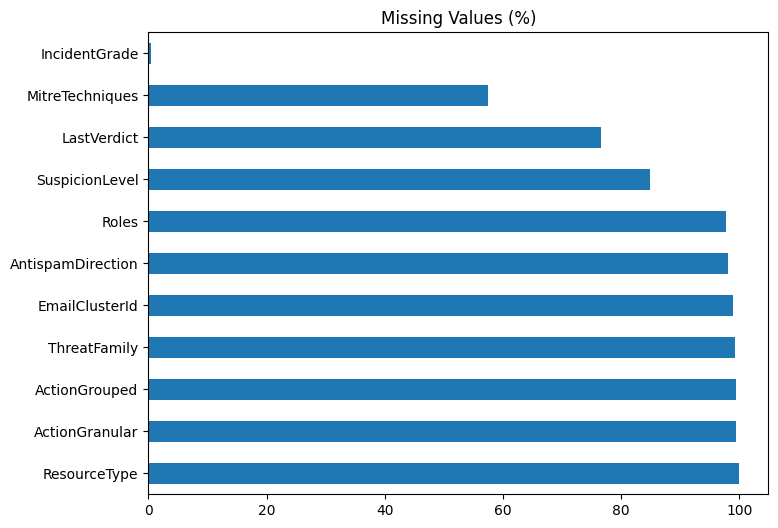

In [ ]:
missing.plot(kind='barh', figsize=(8,6))
plt.title("Missing Values (%)")
plt.show()

In [ ]:
grade = df['IncidentGrade'].value_counts().to_frame("Count")
grade["Percent"] = (grade["Count"] / grade["Count"].sum() * 100).round(2)
grade

,Count,Percent
IncidentGrade,,
BenignPositive,215445,43.32
TruePositive,174991,35.19
FalsePositive,106908,21.50


In [ ]:
df['IncidentGrade'].value_counts().to_frame("Count")

,Count
IncidentGrade,
BenignPositive,215445
TruePositive,174991
FalsePositive,106908


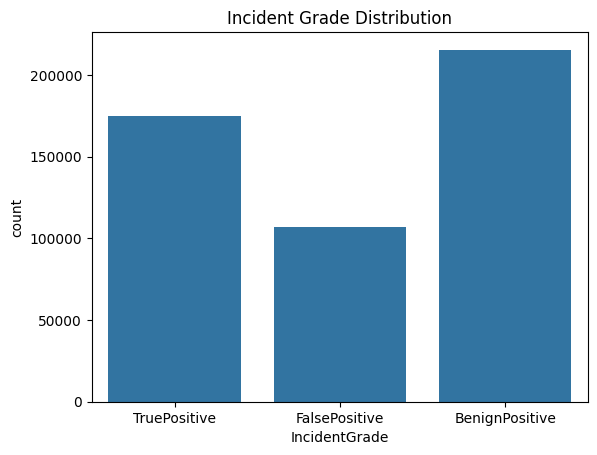

In [ ]:
sns.countplot(data=df, x='IncidentGrade')
plt.title("Incident Grade Distribution")
plt.show()

Category
InitialAccess          225467
Exfiltration            82962
SuspiciousActivity      52773
CommandAndControl       43286
Impact                  39476
CredentialAccess        15774
Execution               14107
Malware                  7552
Discovery                6876
Persistence              3803
DefenseEvasion           2517
LateralMovement          2221
UnwantedSoftware          979
Ransomware                972
Collection                744
PrivilegeEscalation       250
Exploit                   220
CredentialStealing         21
Name: count, dtype: int64


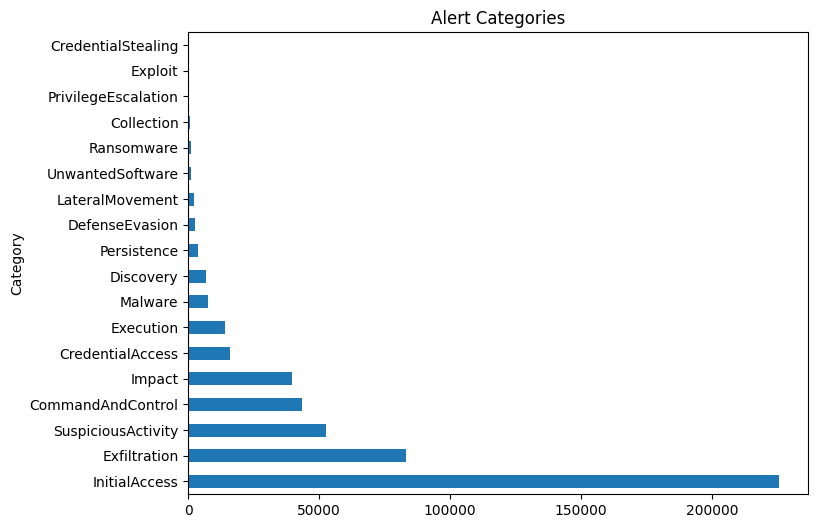

In [ ]:
print(df['Category'].value_counts())

df['Category'].value_counts().plot(kind='barh', figsize=(8,6))
plt.title("Alert Categories")
plt.show()

In [ ]:
df['Category'].value_counts().to_frame("Count")

,Count
Category,
InitialAccess,225467
Exfiltration,82962
SuspiciousActivity,52773
CommandAndControl,43286
Impact,39476
CredentialAccess,15774
Execution,14107
Malware,7552
Discovery,6876


IncidentGrade        BenignPositive  FalsePositive  TruePositive
Category                                                        
Collection                    37.91          49.59         12.50
CommandAndControl             68.37          17.58         14.06
CredentialAccess              39.28          23.69         37.03
CredentialStealing             0.00         100.00          0.00
DefenseEvasion                48.31          28.30         23.39
Discovery                     55.50          26.55         17.95
Execution                     49.92          33.19         16.90
Exfiltration                  69.52          24.04          6.44
Exploit                       49.77          14.61         35.62
Impact                        44.03          22.96         33.01
InitialAccess                 24.83          22.27         52.90
LateralMovement               64.83          21.99         13.18
Malware                       64.31          12.92         22.77
Persistence              

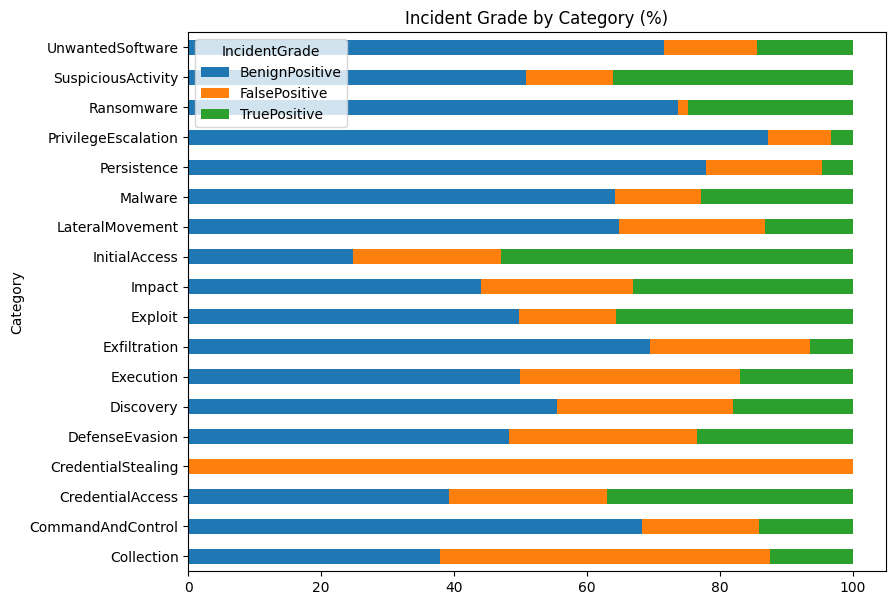

In [ ]:
ct = pd.crosstab(df['Category'], df['IncidentGrade'], normalize='index') * 100
print(ct.round(2))

ct.plot(kind='barh', stacked=True, figsize=(9,7))
plt.title("Incident Grade by Category (%)")
plt.show()

In [ ]:
ct.round(2)

IncidentGrade,BenignPositive,FalsePositive,TruePositive
Category,,,
Collection,37.91,49.59,12.50
CommandAndControl,68.37,17.58,14.06
CredentialAccess,39.28,23.69,37.03
CredentialStealing,0.00,100.00,0.00
DefenseEvasion,48.31,28.30,23.39
Discovery,55.50,26.55,17.95
Execution,49.92,33.19,16.90
Exfiltration,69.52,24.04,6.44
Exploit,49.77,14.61,35.62


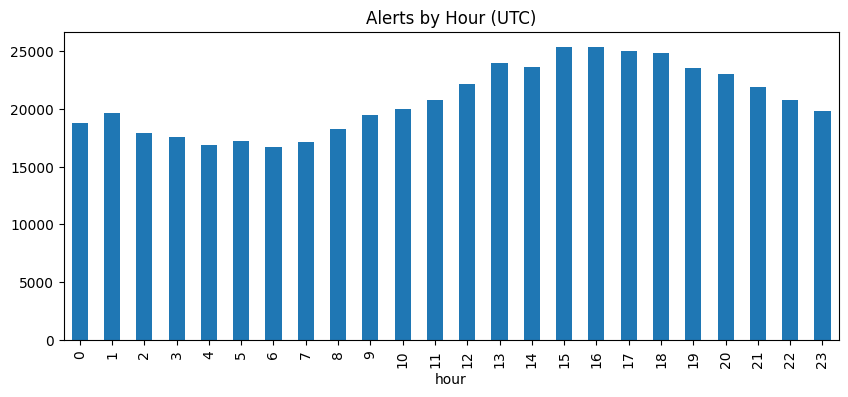

In [ ]:
df['Timestamp'] = pd.to_datetime(df['Timestamp'])
df['hour'] = df['Timestamp'].dt.hour

df['hour'].value_counts().sort_index().plot(kind='bar', figsize=(10,4))
plt.title("Alerts by Hour (UTC)")
plt.show()

In [ ]:
df[['Timestamp','hour']].head()

,Timestamp,hour
0,2024-06-04 06:05:15+00:00,6
1,2024-06-14 03:01:25+00:00,3
2,2024-06-13 04:52:55+00:00,4
3,2024-06-10 16:39:36+00:00,16
4,2024-06-15 01:08:07+00:00,1


In [ ]:
print(df.nunique().sort_values(ascending=False))

AlertId               324281
Timestamp             280300
Id                    190379
IncidentId            160688
AccountUpn            102427
AccountName            69047
AccountSid             66526
AccountObjectId        65693
NetworkMessageId       48975
IpAddress              44590
AlertTitle             33042
FileName               24220
DeviceName             18272
Url                    15661
Sha256                 14793
FolderPath             12424
DeviceId               12103
DetectorId              4559
OrgId                   3868
EmailClusterId          3272
City                    2138
MitreTechniques          836
ThreatFamily             675
State                    638
ApplicationName          351
ResourceIdName           275
ApplicationId            231
RegistryKey              227
CountryCode              151
RegistryValueData        128
RegistryValueName         91
OAuthApplicationId        72
EntityType                27
hour                      24
OSVersion     

In [ ]:
df.nunique().sort_values(ascending=False).to_frame("Unique values")

,Unique values
AlertId,324281
Timestamp,280300
Id,190379
IncidentId,160688
AccountUpn,102427
AccountName,69047
AccountSid,66526
AccountObjectId,65693
NetworkMessageId,48975
IpAddress,44590


In [ ]:
mitre = df['MitreTechniques'].dropna().str.split(';').explode()
print(mitre.value_counts().head(15))

MitreTechniques
T1078        77094
T1078.004    71200
T1566.002    42691
T1566        35124
T1110         9914
T1133         9283
T1566.001     7401
T1110.003     5730
T1110.001     5682
T1071         4970
T1046         4115
T1087         4078
T1087.002     3201
T1190         2818
T1098         2794
Name: count, dtype: int64


In [ ]:
mitre.value_counts().head(15).to_frame("Count")

,Count
MitreTechniques,
T1078,77094
T1078.004,71200
T1566.002,42691
T1566,35124
T1110,9914
T1133,9283
T1566.001,7401
T1110.003,5730
T1110.001,5682


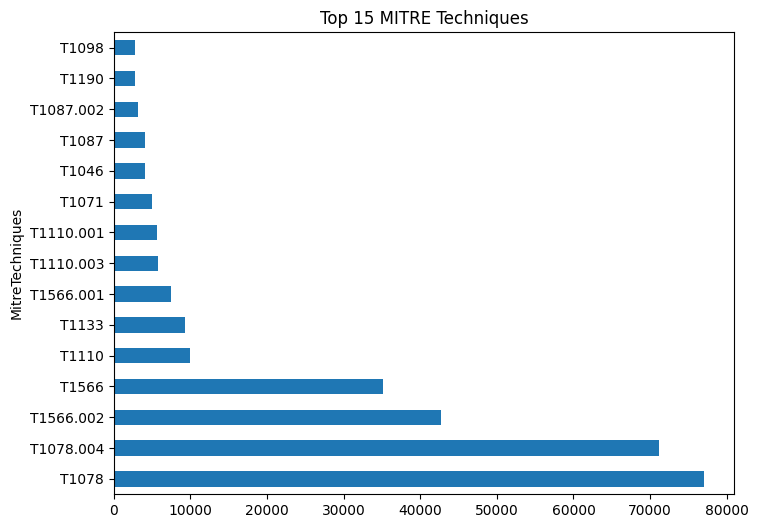

In [ ]:
mitre.value_counts().head(15).plot(kind='barh', figsize=(8,6))
plt.title("Top 15 MITRE Techniques")
plt.show()

In [ ]:
print(df['EntityType'].value_counts())

EntityType
Ip                       114325
User                     101887
MailMessage               61507
Machine                   36457
Url                       35946
File                      35919
CloudLogonRequest         33641
Mailbox                   25387
Process                   18250
MailCluster               11921
CloudApplication          11525
CloudLogonSession         11135
RegistryValue               622
AzureResource               458
RegistryKey                 415
GenericEntity               231
OAuthApplication            128
Malware                     119
SecurityGroup                70
Blob                         20
BlobContainer                13
MailboxConfiguration         13
Nic                           5
AmazonResource                2
IoTDevice                     2
ActiveDirectoryDomain         1
Container                     1
Name: count, dtype: int64


In [ ]:
df['EntityType'].value_counts().to_frame("Count")

,Count
EntityType,
Ip,114325
User,101887
MailMessage,61507
Machine,36457
Url,35946
File,35919
CloudLogonRequest,33641
Mailbox,25387
Process,18250


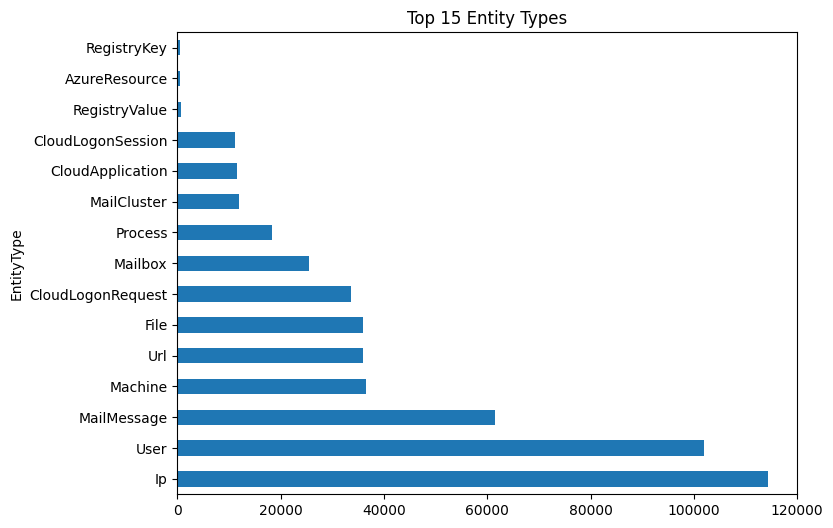

In [ ]:
df['EntityType'].value_counts().head(15).plot(kind='barh', figsize=(8,6))
plt.title("Top 15 Entity Types")
plt.show()

In [ ]:
et = pd.crosstab(df['EntityType'], df['IncidentGrade'], normalize='index').mul(100).round(2)
print(et)

IncidentGrade          BenignPositive  FalsePositive  TruePositive
EntityType                                                        
ActiveDirectoryDomain            0.00         100.00          0.00
AmazonResource                 100.00           0.00          0.00
AzureResource                   81.72           5.95         12.33
Blob                            15.00          85.00          0.00
BlobContainer                   15.38          84.62          0.00
CloudApplication                39.36          27.96         32.69
CloudLogonRequest                1.96          15.90         82.14
CloudLogonSession                2.08          39.89         58.02
Container                      100.00           0.00          0.00
File                            65.61          19.90         14.49
GenericEntity                   66.67          15.15         18.18
IoTDevice                        0.00           0.00        100.00
Ip                              31.78          21.58         4

In [ ]:
et

IncidentGrade,BenignPositive,FalsePositive,TruePositive
EntityType,,,
ActiveDirectoryDomain,0.00,100.00,0.00
AmazonResource,100.00,0.00,0.00
AzureResource,81.72,5.95,12.33
Blob,15.00,85.00,0.00
BlobContainer,15.38,84.62,0.00
CloudApplication,39.36,27.96,32.69
CloudLogonRequest,1.96,15.90,82.14
CloudLogonSession,2.08,39.89,58.02
Container,100.00,0.00,0.00


In [ ]:
er = pd.crosstab(df['EvidenceRole'], df['IncidentGrade'], normalize='index').mul(100).round(2)
print(er)

IncidentGrade  BenignPositive  FalsePositive  TruePositive
EvidenceRole                                              
Impacted                50.43          22.62         26.95
Related                 37.49          20.57         41.93


In [ ]:
er

IncidentGrade,BenignPositive,FalsePositive,TruePositive
EvidenceRole,,,
Impacted,50.43,22.62,26.95
Related,37.49,20.57,41.93


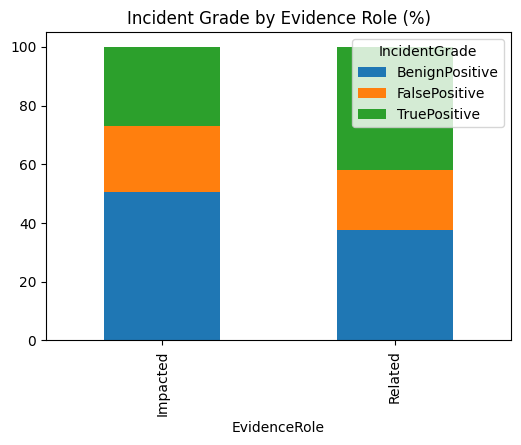

In [ ]:
er.plot(kind='bar', stacked=True, figsize=(6,4))
plt.title("Incident Grade by Evidence Role (%)")
plt.show()

In [ ]:
lv = pd.crosstab(df['LastVerdict'], df['IncidentGrade'], normalize='index').mul(100).round(2)
print(lv)

IncidentGrade                                       BenignPositive  \
LastVerdict                                                          
DomainPII_50d8b4a941c26b89482c94ab324b5a274f9ced66           50.00   
DomainPII_9207384283ce115db5a590dd9ca5de21e5e99df2            0.00   
Malicious                                                    56.24   
NoThreatsFound                                               53.11   
Suspicious                                                   62.25   

IncidentGrade                                       FalsePositive  \
LastVerdict                                                         
DomainPII_50d8b4a941c26b89482c94ab324b5a274f9ced66           0.00   
DomainPII_9207384283ce115db5a590dd9ca5de21e5e99df2           0.00   
Malicious                                                   12.56   
NoThreatsFound                                              17.58   
Suspicious                                                  15.58   

IncidentGrade            

In [ ]:
lv

IncidentGrade,BenignPositive,FalsePositive,TruePositive
LastVerdict,,,
DomainPII_50d8b4a941c26b89482c94ab324b5a274f9ced66,50.00,0.00,50.00
DomainPII_9207384283ce115db5a590dd9ca5de21e5e99df2,0.00,0.00,100.00
Malicious,56.24,12.56,31.20
NoThreatsFound,53.11,17.58,29.31
Suspicious,62.25,15.58,22.17


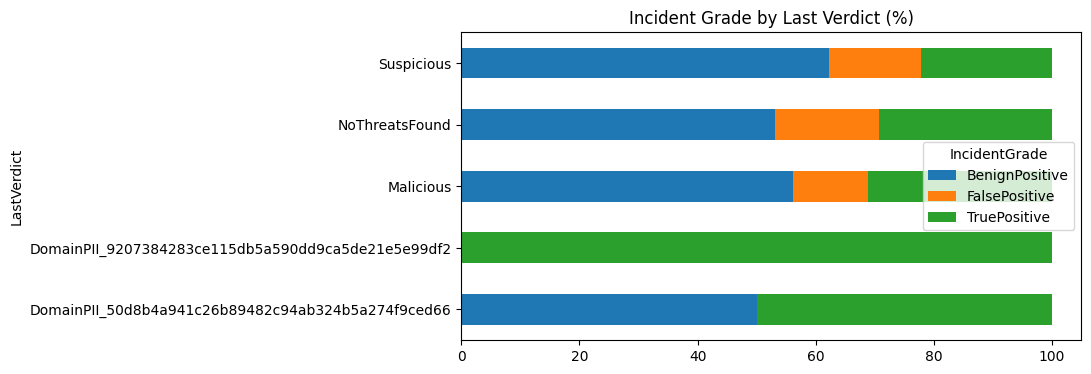

In [ ]:
lv.plot(kind='barh', stacked=True, figsize=(8,4))
plt.title("Incident Grade by Last Verdict (%)")
plt.show()

In [ ]:
alerts_per_incident = df.groupby('IncidentId')['AlertId'].nunique()
print(alerts_per_incident.describe())

count    160688.000000
mean          2.188334
std          15.925857
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max        1252.000000
Name: AlertId, dtype: float64


In [ ]:
alerts_per_incident.describe().to_frame("Alerts per incident")

,Alerts per incident
count,160688.000000
mean,2.188334
std,15.925857
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,1252.000000


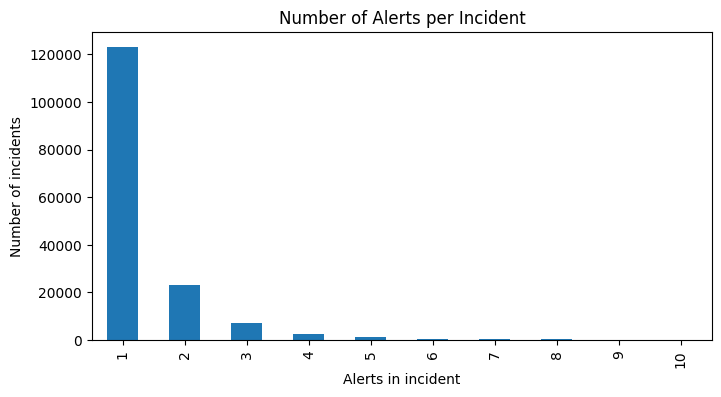

In [ ]:
alerts_per_incident.value_counts().sort_index().head(10).plot(kind='bar', figsize=(8,4))
plt.title("Number of Alerts per Incident")
plt.xlabel("Alerts in incident")
plt.ylabel("Number of incidents")
plt.show()

In [ ]:
org = df['OrgId'].value_counts()
print("Top 10 orgs share (%):", round(org.head(10).sum() / len(df) * 100, 2))

Top 10 orgs share (%): 24.87


In [ ]:
org.head(10).to_frame("Rows")

,Rows
OrgId,
0,44382
2,12509
1,11048
3,9957
5,9144
6,8352
4,7591
10,7215
7,7118


In [ ]:
ra = pd.crosstab(df['ActionGrouped'], df['IncidentGrade'])
print(ra)

IncidentGrade          BenignPositive  FalsePositive  TruePositive
ActionGrouped                                                     
ContainAccount                     47             66            92
IsolateDevice                      13              5            30
Stop Virtual Machines               1              0             0


In [ ]:
ra

IncidentGrade,BenignPositive,FalsePositive,TruePositive
ActionGrouped,,,
ContainAccount,47,66,92
IsolateDevice,13,5,30
Stop Virtual Machines,1,0,0


In [ ]:
for col in ['CountryCode', 'State', 'City', 'OSFamily', 'OSVersion', 'DeviceId', 'Url']:
    top = df[col].value_counts(normalize=True).iloc[0] * 100
    print(col, "- most common value covers", round(top, 2), "% of rows")

CountryCode - most common value covers 92.13 % of rows
State - most common value covers 93.35 % of rows
City - most common value covers 93.34 % of rows
OSFamily - most common value covers 98.0 % of rows
OSVersion - most common value covers 98.0 % of rows
DeviceId - most common value covers 96.23 % of rows
Url - most common value covers 92.81 % of rows


In [ ]:
hidden = {col: round(df[col].value_counts(normalize=True).iloc[0] * 100, 2)
          for col in ['CountryCode', 'State', 'City', 'OSFamily', 'OSVersion', 'DeviceId', 'Url']}
pd.Series(hidden).to_frame("Most common value %")

,Most common value %
CountryCode,92.13
State,93.35
City,93.34
OSFamily,98.00
OSVersion,98.00
DeviceId,96.23
Url,92.81


In [ ]:
import os

folder_path = "/content/drive/MyDrive/Microsoft_GUIDE_Dataset"

print(os.listdir(folder_path))

['GUIDE_Train.csv']


In [ ]:
import pandas as pd

file_path = folder_path + "/GUIDE_Train.csv"

df_sample = pd.read_csv(file_path, nrows=1000)

print(df_sample.shape)
print(df_sample.head())

(1000, 45)
              Id  OrgId  IncidentId  AlertId                 Timestamp  \
0   180388628218      0         612   123247  2024-06-04T06:05:15.000Z   
1   455266534868     88         326   210035  2024-06-14T03:01:25.000Z   
2  1056561957389    809       58352   712507  2024-06-13T04:52:55.000Z   
3  1279900258736     92       32992   774301  2024-06-10T16:39:36.000Z   
4   214748368522    148        4359   188041  2024-06-15T01:08:07.000Z   

   DetectorId  AlertTitle           Category MitreTechniques   IncidentGrade  \
0           7           6      InitialAccess             NaN    TruePositive   
1          58          43       Exfiltration             NaN   FalsePositive   
2         423         298      InitialAccess           T1189   FalsePositive   
3           2           2  CommandAndControl             NaN  BenignPositive   
4           9          74          Execution             NaN    TruePositive   

   ... ResourceType Roles OSFamily OSVersion  AntispamDirection

In [ ]:
import glob
print(glob.glob('/content/drive/MyDrive/**/GUIDE*.csv', recursive=True))

['/content/drive/MyDrive/Microsoft_GUIDE_Dataset/GUIDE_Train.csv']


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

drive.mount('/content/drive')
file_path = '/content/drive/MyDrive/Microsoft_GUIDE_Dataset/GUIDE_Train.csv'

df = pd.read_csv(file_path, nrows=500000)
df['Timestamp'] = pd.to_datetime(df['Timestamp'])
df['hour'] = df['Timestamp'].dt.hour
et = pd.crosstab(df['EntityType'], df['IncidentGrade'], normalize='index').mul(100).round(2)

print("Reloaded! Shape:", df.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Reloaded! Shape: (500000, 46)


In [ ]:
df['Intrusion'] = df['IncidentGrade'].map({'TruePositive': 'Intrusion',
                                           'BenignPositive': 'Non-intrusion',
                                           'FalsePositive': 'Non-intrusion'})
print(df['Intrusion'].value_counts())

Intrusion
Non-intrusion    322353
Intrusion        174991
Name: count, dtype: int64


In [ ]:
intr_table = df['Intrusion'].value_counts().to_frame("Count")
intr_table["Percent"] = (intr_table["Count"] / intr_table["Count"].sum() * 100).round(2)
intr_table

,Count,Percent
Intrusion,,
Non-intrusion,322353,64.81
Intrusion,174991,35.19


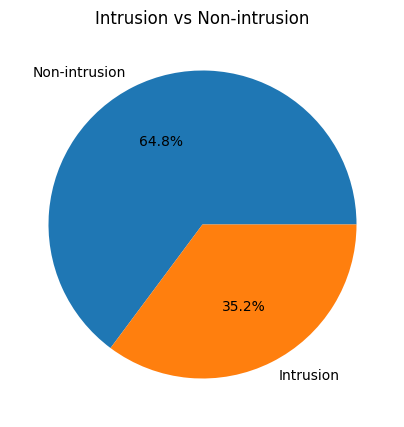

In [ ]:
df['Intrusion'].value_counts().plot(kind='pie', autopct='%1.1f%%', figsize=(5,5))
plt.title("Intrusion vs Non-intrusion")
plt.ylabel("")
plt.show()

In [ ]:
intr = df[df['Intrusion'] == 'Intrusion']
print(intr['Category'].value_counts())

Category
InitialAccess          119049
SuspiciousActivity      18856
Impact                  13029
CommandAndControl        6078
CredentialAccess         5831
Exfiltration             5252
Execution                2378
Malware                  1714
Discovery                1223
DefenseEvasion            582
LateralMovement           287
Ransomware                220
Persistence               175
UnwantedSoftware          140
Collection                 91
Exploit                    78
PrivilegeEscalation         8
Name: count, dtype: int64


In [ ]:
intr['Category'].value_counts().to_frame("Intrusion count")

,Intrusion count
Category,
InitialAccess,119049
SuspiciousActivity,18856
Impact,13029
CommandAndControl,6078
CredentialAccess,5831
Exfiltration,5252
Execution,2378
Malware,1714
Discovery,1223


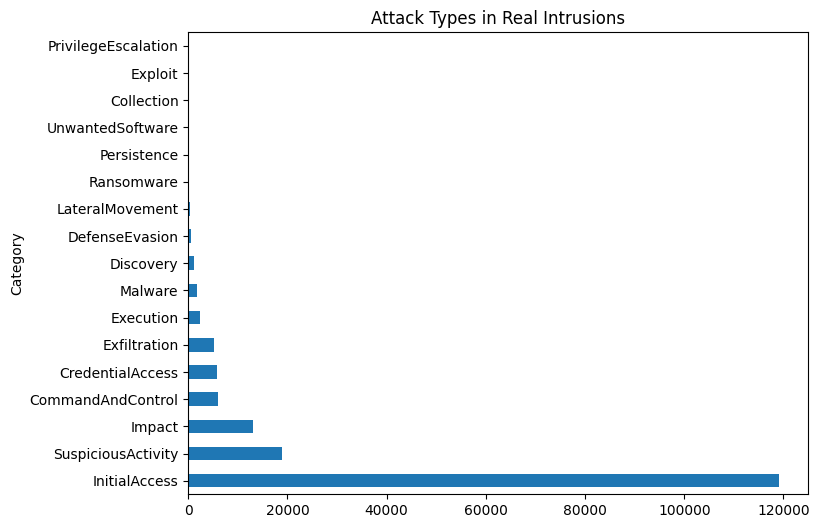

In [ ]:
intr['Category'].value_counts().plot(kind='barh', figsize=(8,6))
plt.title("Attack Types in Real Intrusions")
plt.show()

In [ ]:
intr_mitre = intr['MitreTechniques'].dropna().str.split(';').explode()
print(intr_mitre.value_counts().head(10))

MitreTechniques
T1078        53336
T1078.004    53113
T1566.002    15436
T1566         7379
T1110         5355
T1110.003     4729
T1110.001     4671
T1566.001     2078
T1595          566
T1087          513
Name: count, dtype: int64


In [ ]:
intr_mitre.value_counts().head(10).to_frame("Count")

,Count
MitreTechniques,
T1078,53336
T1078.004,53113
T1566.002,15436
T1566,7379
T1110,5355
T1110.003,4729
T1110.001,4671
T1566.001,2078
T1595,566


In [ ]:
hour_intr = pd.crosstab(df['hour'], df['Intrusion'], normalize='index') * 100
print(hour_intr.round(2))

Intrusion  Intrusion  Non-intrusion
hour                               
0              37.63          62.37
1              37.27          62.73
2              38.98          61.02
3              39.77          60.23
4              40.33          59.67
5              40.90          59.10
6              40.47          59.53
7              37.96          62.04
8              37.95          62.05
9              36.23          63.77
10             35.54          64.46
11             35.10          64.90
12             32.40          67.60
13             32.87          67.13
14             32.68          67.32
15             31.07          68.93
16             32.16          67.84
17             32.46          67.54
18             31.84          68.16
19             33.57          66.43
20             32.54          67.46
21             33.59          66.41
22             34.75          65.25
23             36.15          63.85


In [ ]:
hour_intr.round(2)

Intrusion,Intrusion,Non-intrusion
hour,,
0,37.63,62.37
1,37.27,62.73
2,38.98,61.02
3,39.77,60.23
4,40.33,59.67
5,40.90,59.10
6,40.47,59.53
7,37.96,62.04
8,37.95,62.05


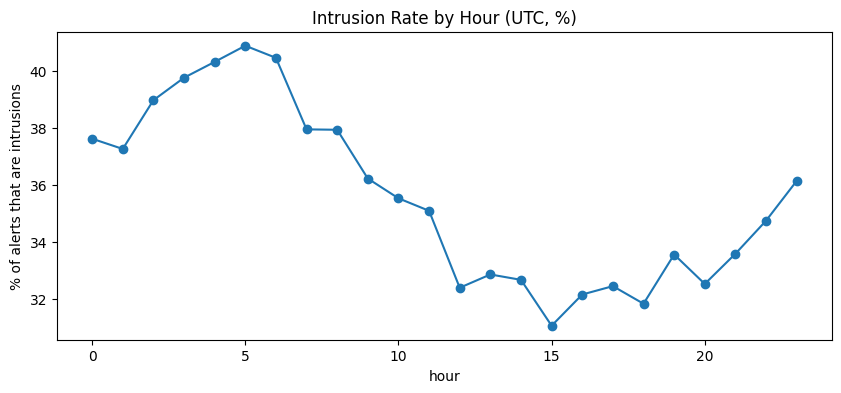

In [ ]:
hour_intr['Intrusion'].plot(kind='line', marker='o', figsize=(10,4))
plt.title("Intrusion Rate by Hour (UTC, %)")
plt.ylabel("% of alerts that are intrusions")
plt.show()

In [ ]:
df['date'] = df['Timestamp'].dt.date
daily = df.groupby('date').size()
print(daily)

date
2023-12-01        1
2023-12-08        2
2023-12-13        1
2023-12-15        2
2023-12-19        1
              ...  
2024-06-13    35155
2024-06-14    24835
2024-06-15     9308
2024-06-16     7561
2024-06-17     2114
Length: 90, dtype: int64


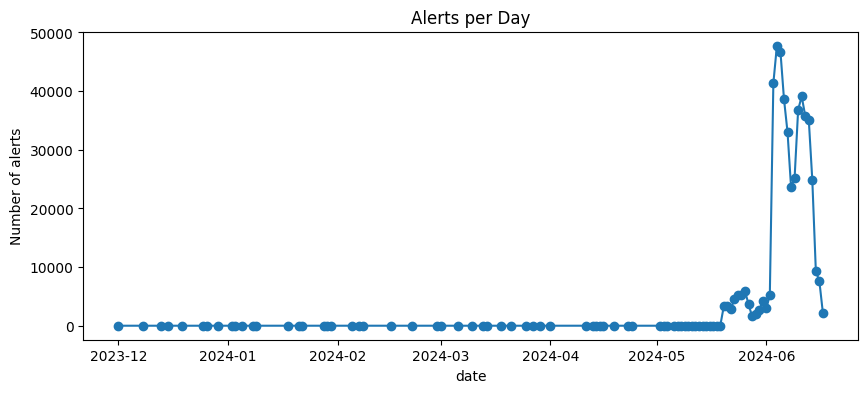

In [ ]:
daily.plot(kind='line', marker='o', figsize=(10,4))
plt.title("Alerts per Day")
plt.ylabel("Number of alerts")
plt.show()

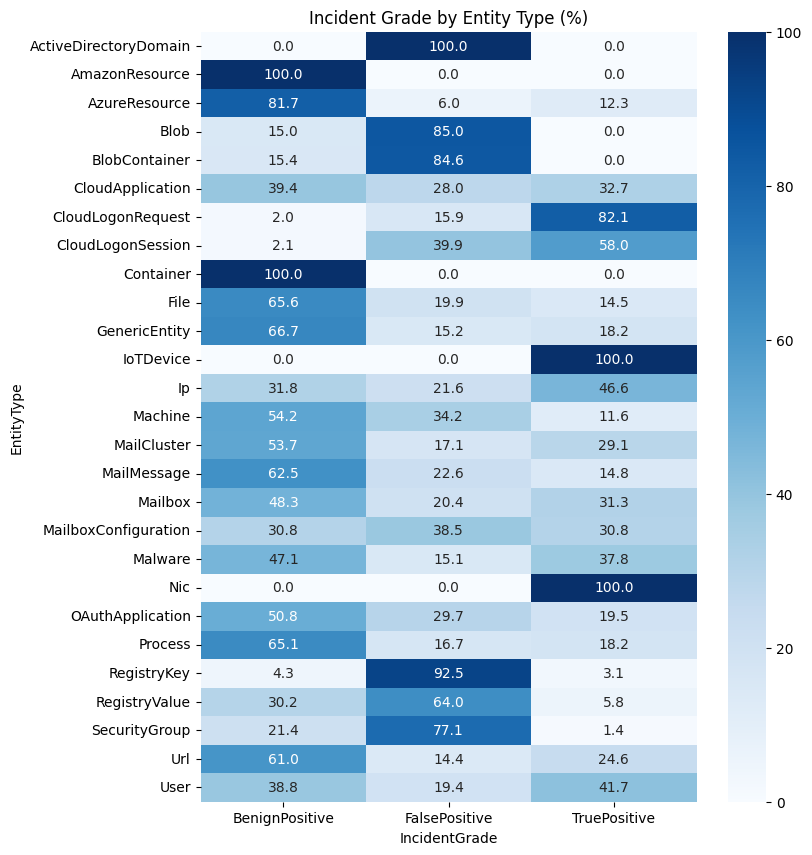

In [ ]:
plt.figure(figsize=(8,10))
sns.heatmap(et, annot=True, fmt='.1f', cmap='Blues')
plt.title("Incident Grade by Entity Type (%)")
plt.show()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

drive.mount('/content/drive')
file_path = '/content/drive/MyDrive/Microsoft_GUIDE_Dataset/GUIDE_Train.csv'

df = pd.read_csv(file_path, nrows=500000)
df['Timestamp'] = pd.to_datetime(df['Timestamp'])
df['hour'] = df['Timestamp'].dt.hour
et = pd.crosstab(df['EntityType'], df['IncidentGrade'], normalize='index').mul(100).round(2)

print("Reloaded! Shape:", df.shape)

Mounted at /content/drive
Reloaded! Shape: (500000, 46)


In [ ]:
print(df['IncidentGrade'].value_counts())

IncidentGrade
BenignPositive    215445
TruePositive      174991
FalsePositive     106908
Name: count, dtype: int64


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Load 50,000 rows for an initial experiment
data = pd.read_csv(file_path, nrows=50000)

# Select numeric features
X = data.select_dtypes(include=['number']).copy()

# Remove identifiers to avoid misleading predictions
id_columns = [
    'Id', 'OrgId', 'IncidentId', 'AlertId',
    'DetectorId', 'DeviceId', 'AccountSid'
]

X = X.drop(columns=id_columns, errors='ignore')

# Target
y = data['IncidentGrade']

# Remove rows with missing target labels
valid = y.notna()
X = X.loc[valid]
y = y.loc[valid]

# Handle missing numeric values
X = X.fillna(X.median()).fillna(0)

# Split training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42,
    stratify=y
)

# Train model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)

# Accuracy
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

# Other evaluation metrics
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 72.05 %
                precision    recall  f1-score   support

BenignPositive       0.71      0.81      0.76      4305
 FalsePositive       0.67      0.49      0.57      2156
  TruePositive       0.76      0.75      0.76      3484

      accuracy                           0.72      9945
     macro avg       0.71      0.68      0.69      9945
  weighted avg       0.72      0.72      0.72      9945

